# 00 — Baseline: Data Loading, Preprocessing & Visualisation

**EEEM068 Applied Machine Learning — University of Surrey**  
**Dataset:** Kaggle Diabetic Retinopathy Detection  
**Purpose:** Load train/test data from multi-part archives, explore class distribution, understand image quality issues, build and validate the shared PyTorch pipeline.

---

### Notebook objectives
1. Mount and extract multi-part dataset archives
2. Load `trainLabels.csv` and map to image files
3. Quantify and visualise class imbalance
4. Inspect image quality (resolution, focus, exposure, orientation)
5. Build shared `DRDataset` + `DataLoader` pipeline
6. Validate pipeline output (shapes, dtypes, normalisation)
7. Define and document ALL evaluation metrics used across experiments

## 1. Environment Setup & Imports

In [6]:
import os
import sys
import random
import warnings
import zipfile
import glob
import shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image, ImageStat
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from torchvision import transforms

warnings.filterwarnings('ignore')

# ── Reproducibility ────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f'PyTorch  : {torch.__version__}')
print(f'CUDA     : {torch.cuda.is_available()}')
print(f'Device   : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}')

PyTorch  : 2.11.0+cu130
CUDA     : True
Device   : NVIDIA RTX A4000


## 2. Path Configuration

In [7]:
# ── Update these paths to match your local setup ──────────────
# The dataset is split into multi-part archives:
#   train.zip.001 ... train.zip.005  (training images)
#   test.zip.001  ... test.zip.007   (test images)
#   trainLabels.csv                  (DR grade per image)

DATA_ROOT    = Path('data/diabetic-retinopathy-detection')               # root folder
TRAIN_DIR    = DATA_ROOT / 'train'        # extracted training images
TEST_DIR     = DATA_ROOT / 'test'         # extracted test images
LABELS_CSV   = DATA_ROOT / 'trainLabels.csv'
OUTPUT_DIR   = Path('outputs')
FIGURES_DIR  = OUTPUT_DIR / 'figures'
CKPT_DIR     = OUTPUT_DIR / 'checkpoints'
RESULTS_DIR  = Path('results')

for d in [FIGURES_DIR, CKPT_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CLASS_NAMES  = {0:'No DR', 1:'Mild', 2:'Moderate', 3:'Severe', 4:'Proliferative DR'}
CLASS_COLORS = ['#2ECC71','#F39C12','#E67E22','#E74C3C','#8E44AD']
NUM_CLASSES  = 5

print('Paths configured. Checking existence:')
for p in [TRAIN_DIR, TEST_DIR, LABELS_CSV]:
    status = '✓' if p.exists() else '✗ NOT FOUND'
    print(f'  {status}  {p}')

Paths configured. Checking existence:
  ✓  data/diabetic-retinopathy-detection/train
  ✓  data/diabetic-retinopathy-detection/test
  ✓  data/diabetic-retinopathy-detection/trainLabels.csv


## 3. Multi-Part Archive Extraction

> The dataset arrives as `train.zip.001`...`train.zip.005` and `test.zip.001`...`test.zip.007`. Run this cell once to extract. Skip if already extracted.

In [ ]:
def extract_multipart(archive_pattern: str, dest_dir: Path, dry_run: bool = True):
    """Extract multi-part zip archives (7zip format) to dest_dir.

    Args:
        archive_pattern : glob pattern for the archive parts, e.g. 'data/train.zip.*'
        dest_dir        : destination folder for extracted files
        dry_run         : if True, only prints what would be extracted without doing it
    """
    parts = sorted(glob.glob(archive_pattern))
    if not parts:
        print(f'No files found matching: {archive_pattern}')
        return
    print(f'Found {len(parts)} archive parts:')
    for p in parts:
        print(f'  {p}  ({os.path.getsize(p)/1e9:.2f} GB)')
    if dry_run:
        print('\nDry run — set dry_run=False to extract')
        return

    # 7zip merges parts automatically when you pass the .001 file
    import subprocess
    cmd = ['7z', 'x', parts[0], f'-o{dest_dir}', '-y']
    print(f'\nRunning: {" ".join(cmd)}')
    subprocess.run(cmd, check=True)
    print(f'Extraction complete → {dest_dir}')


def flatten_archive_output(dest_dir: Path) -> None:
    """Move files out of a nested folder created by archive extraction."""
    nested = dest_dir / dest_dir.name
    if nested.exists() and nested.is_dir():
        print(f'Flattening nested extraction directory: {nested}')
        for item in nested.iterdir():
            target = dest_dir / item.name
            if item.is_file() and not target.exists():
                shutil.move(str(item), str(target))
            elif item.is_dir():
                shutil.move(str(item), str(target))
        nested.rmdir()
        print(f'Flattened contents into: {dest_dir}')


# ── Extract archive parts ──
extract_multipart(str(DATA_ROOT / 'train.zip.*'), TRAIN_DIR, dry_run=False)
flatten_archive_output(TRAIN_DIR)
extract_multipart(str(DATA_ROOT / 'test.zip.*'),  TEST_DIR,  dry_run=False)
flatten_archive_output(TEST_DIR)

Found 5 archive parts:
  data/diabetic-retinopathy-detection/train.zip.001  (8.39 GB)
  data/diabetic-retinopathy-detection/train.zip.002  (8.39 GB)
  data/diabetic-retinopathy-detection/train.zip.003  (8.39 GB)
  data/diabetic-retinopathy-detection/train.zip.004  (8.39 GB)
  data/diabetic-retinopathy-detection/train.zip.005  (1.43 GB)

Running: 7z x data/diabetic-retinopathy-detection/train.zip.001 -odata/diabetic-retinopathy-detection/train -y

7-Zip (A) 4.57  Copyright (c) 1999-2007 Igor Pavlov  2007-12-06
p7zip Version 4.57 (locale=en_GB.UTF-8,Utf16=on,HugeFiles=on,32 CPUs)

Processing archive: data/diabetic-retinopathy-detection/train.zip.001

Extracting  train
Extracting  train/10003_left.jpeg
Extracting  train/10003_right.jpeg
Extracting  train/10007_left.jpeg
Extracting  train/10007_right.jpeg
Extracting  train/10009_left.jpeg
Extracting  train/10009_right.jpeg
Extracting  train/1000_left.jpeg
Extracting  train/1000_right.jpeg
Extracting  train/10010_left.jpeg
Extracting  train

In [8]:
# ── Verify extraction and concatenation ─────────────────
train_parts = sorted(DATA_ROOT.glob('train.zip.*'))
test_parts  = sorted(DATA_ROOT.glob('test.zip.*'))
print(f'Archive parts:')
print(f'  Train: {len(train_parts)} parts')
print(f'  Test:  {len(test_parts)} parts')
print(f'\nExtracted and concatenated:')
print(f'  Train folder: {len(list(TRAIN_DIR.glob("*.jpeg"))):,} images')
print(f'  Test folder:  {len(list(TEST_DIR.glob("*.jpeg"))):,} images')


Archive parts:
  Train: 5 parts
  Test:  7 parts

Extracted and concatenated:
  Train folder: 35,126 images
  Test folder:  53,576 images


## 4. Load Labels & Dataset Inventory

In [9]:
# ── Load trainLabels.csv ───────────────────────────────────────
df = pd.read_csv(LABELS_CSV)
print(f'trainLabels.csv: {len(df):,} rows')
print(df.head(8))
print(f'\nColumns: {list(df.columns)}')
print(f'Grade range: {df["level"].min()} – {df["level"].max()}')

trainLabels.csv: 35,126 rows
      image  level
0   10_left      0
1  10_right      0
2   13_left      0
3  13_right      0
4   15_left      1
5  15_right      2
6   16_left      4
7  16_right      4

Columns: ['image', 'level']
Grade range: 0 – 4


In [10]:
# ── Parse left/right eye from image name ──────────────────────
# Image name format: {patient_id}_{left|right}
# e.g. '1_left'  → patient_id=1, eye=left

df['patient_id'] = df['image'].str.extract(r'^(\d+)_').astype(int)
df['eye']        = df['image'].str.extract(r'_(left|right)$')
df['img_path']   = df['image'].apply(lambda x: TRAIN_DIR / f'{x}.jpeg')
df['file_exists'] = df['img_path'].apply(lambda p: p.exists())

print(f'Total images       : {len(df):,}')
print(f'Files found on disk: {df["file_exists"].sum():,}')
print(f'Files MISSING      : {(~df["file_exists"]).sum():,}')
print(f'\nUnique patients    : {df["patient_id"].nunique():,}')
print(f'Left eye images    : {(df["eye"]=="left").sum():,}')
print(f'Right eye images   : {(df["eye"]=="right").sum():,}')

# Keep only images that exist
df = df[df['file_exists']].reset_index(drop=True)
print(f'\nWorking dataset    : {len(df):,} images')

Total images       : 35,126
Files found on disk: 35,126
Files MISSING      : 0

Unique patients    : 17,563
Left eye images    : 17,563
Right eye images   : 17,563

Working dataset    : 35,126 images


In [11]:
# ── Load test images ───────────────────────────────────────
test_images = list(TEST_DIR.glob('*.jpeg'))
df_test = pd.DataFrame({'image': [f.stem for f in test_images], 'img_path': test_images})
df_test['file_exists'] = df_test['img_path'].apply(lambda p: p.exists())
df_test = df_test[df_test['file_exists']].reset_index(drop=True)
print(f'Test dataset: {len(df_test):,} images')
print(df_test.head())

Test dataset: 53,576 images
         image                                           img_path  file_exists
0  41839_right  data/diabetic-retinopathy-detection/test/41839...         True
1    9397_left  data/diabetic-retinopathy-detection/test/9397_...         True
2  30863_right  data/diabetic-retinopathy-detection/test/30863...         True
3  27119_right  data/diabetic-retinopathy-detection/test/27119...         True
4  34055_right  data/diabetic-retinopathy-detection/test/34055...         True


## 5. Class Distribution Analysis

> **Critical section.** The DR dataset is severely imbalanced. This directly affects model training strategy and evaluation metric selection.

In [13]:
# ── Class counts and percentages ──────────────────────────────
class_counts = df['level'].value_counts().sort_index()
class_pcts   = (class_counts / len(df) * 100).round(2)

print('CLASS DISTRIBUTION')
print('='*52)
for g, cnt, pct in zip(class_counts.index, class_counts.values, class_pcts.values):
    bar = '█' * int(pct)
    print(f'  Grade {g} | {CLASS_NAMES[g]:18s} | {cnt:6,} ({pct:5.1f}%) {bar}')
print('='*52)
print(f'  TOTAL                       | {len(df):6,} (100.0%)')

# Imbalance ratio
max_cls = class_counts.max()
min_cls = class_counts.min()
print(f'\nImbalance ratio (max/min): {max_cls/min_cls:.1f}x')
print(f'Majority class (Grade 0): {class_pcts[0]:.1f}% of all data')

CLASS DISTRIBUTION
  Grade 0 | No DR              | 25,810 ( 73.5%) █████████████████████████████████████████████████████████████████████████
  Grade 1 | Mild               |  2,443 (  7.0%) ██████
  Grade 2 | Moderate           |  5,292 ( 15.1%) ███████████████
  Grade 3 | Severe             |    873 (  2.5%) ██
  Grade 4 | Proliferative DR   |    708 (  2.0%) ██
  TOTAL                       | 35,126 (100.0%)

Imbalance ratio (max/min): 36.5x
Majority class (Grade 0): 73.5% of all data


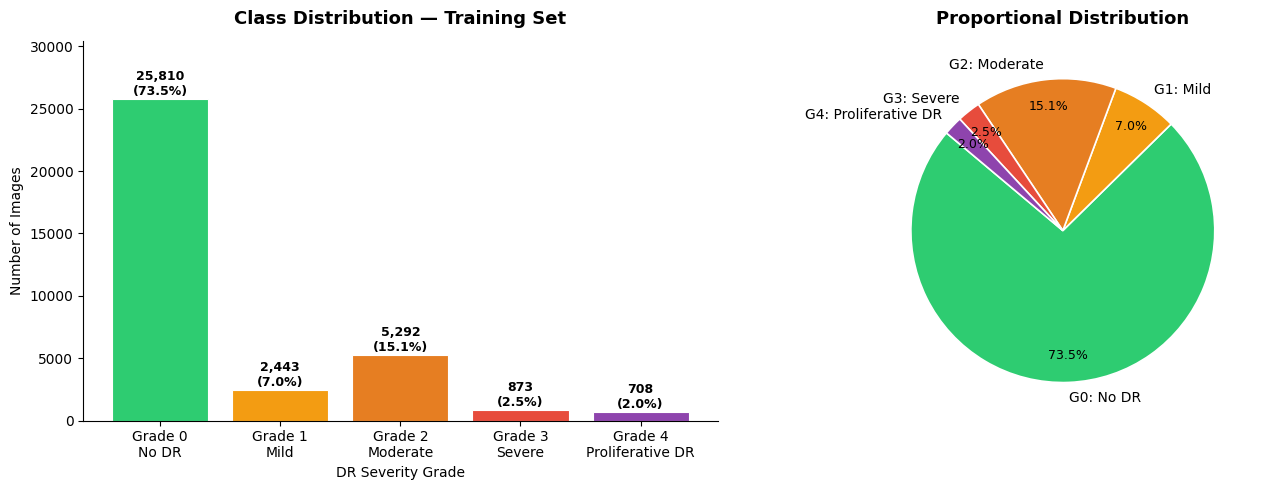

Saved → outputs/figures/class_distribution.png


In [14]:
# ── Figure 1: Class distribution bar chart ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
ax = axes[0]
bars = ax.bar(
    [f'Grade {i}\n{CLASS_NAMES[i]}' for i in range(5)],
    class_counts.values,
    color=CLASS_COLORS, edgecolor='white', linewidth=0.8
)
for bar, cnt, pct in zip(bars, class_counts.values, class_pcts.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 80,
            f'{cnt:,}\n({pct:.1f}%)',
            ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title('Class Distribution — Training Set', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Number of Images')
ax.set_xlabel('DR Severity Grade')
ax.spines[['top','right']].set_visible(False)
ax.set_ylim(0, class_counts.max() * 1.18)

# Pie chart
ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(
    class_counts.values,
    labels=[f'G{i}: {CLASS_NAMES[i]}' for i in range(5)],
    colors=CLASS_COLORS,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.82,
    wedgeprops={'edgecolor':'white','linewidth':1.2}
)
for at in autotexts:
    at.set_fontsize(9)
ax2.set_title('Proportional Distribution', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/figures/class_distribution.png')

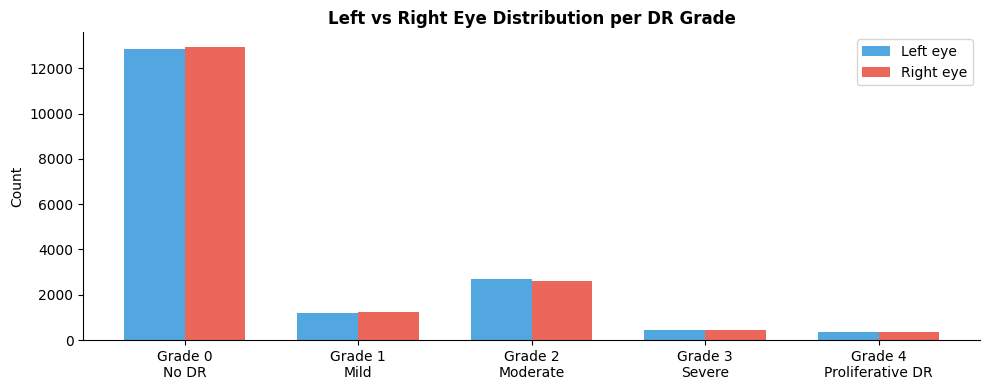

In [15]:
# ── Left vs Right eye distribution per grade ──────────────────
fig, ax = plt.subplots(figsize=(10, 4))
eye_grade = df.groupby(['level','eye']).size().unstack(fill_value=0)

x = np.arange(5)
w = 0.35
ax.bar(x - w/2, eye_grade.get('left',  pd.Series([0]*5)).values,
       w, label='Left eye',  color='#3498DB', alpha=0.85)
ax.bar(x + w/2, eye_grade.get('right', pd.Series([0]*5)).values,
       w, label='Right eye', color='#E74C3C', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels([f'Grade {i}\n{CLASS_NAMES[i]}' for i in range(5)])
ax.set_ylabel('Count')
ax.set_title('Left vs Right Eye Distribution per DR Grade', fontweight='bold')
ax.legend()
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eye_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Image Quality & Characteristics Analysis

> The dataset contains images from different camera models and imaging conditions. Some images are anatomically oriented (standard), others are inverted through a microscope lens. We must understand the data before preprocessing.

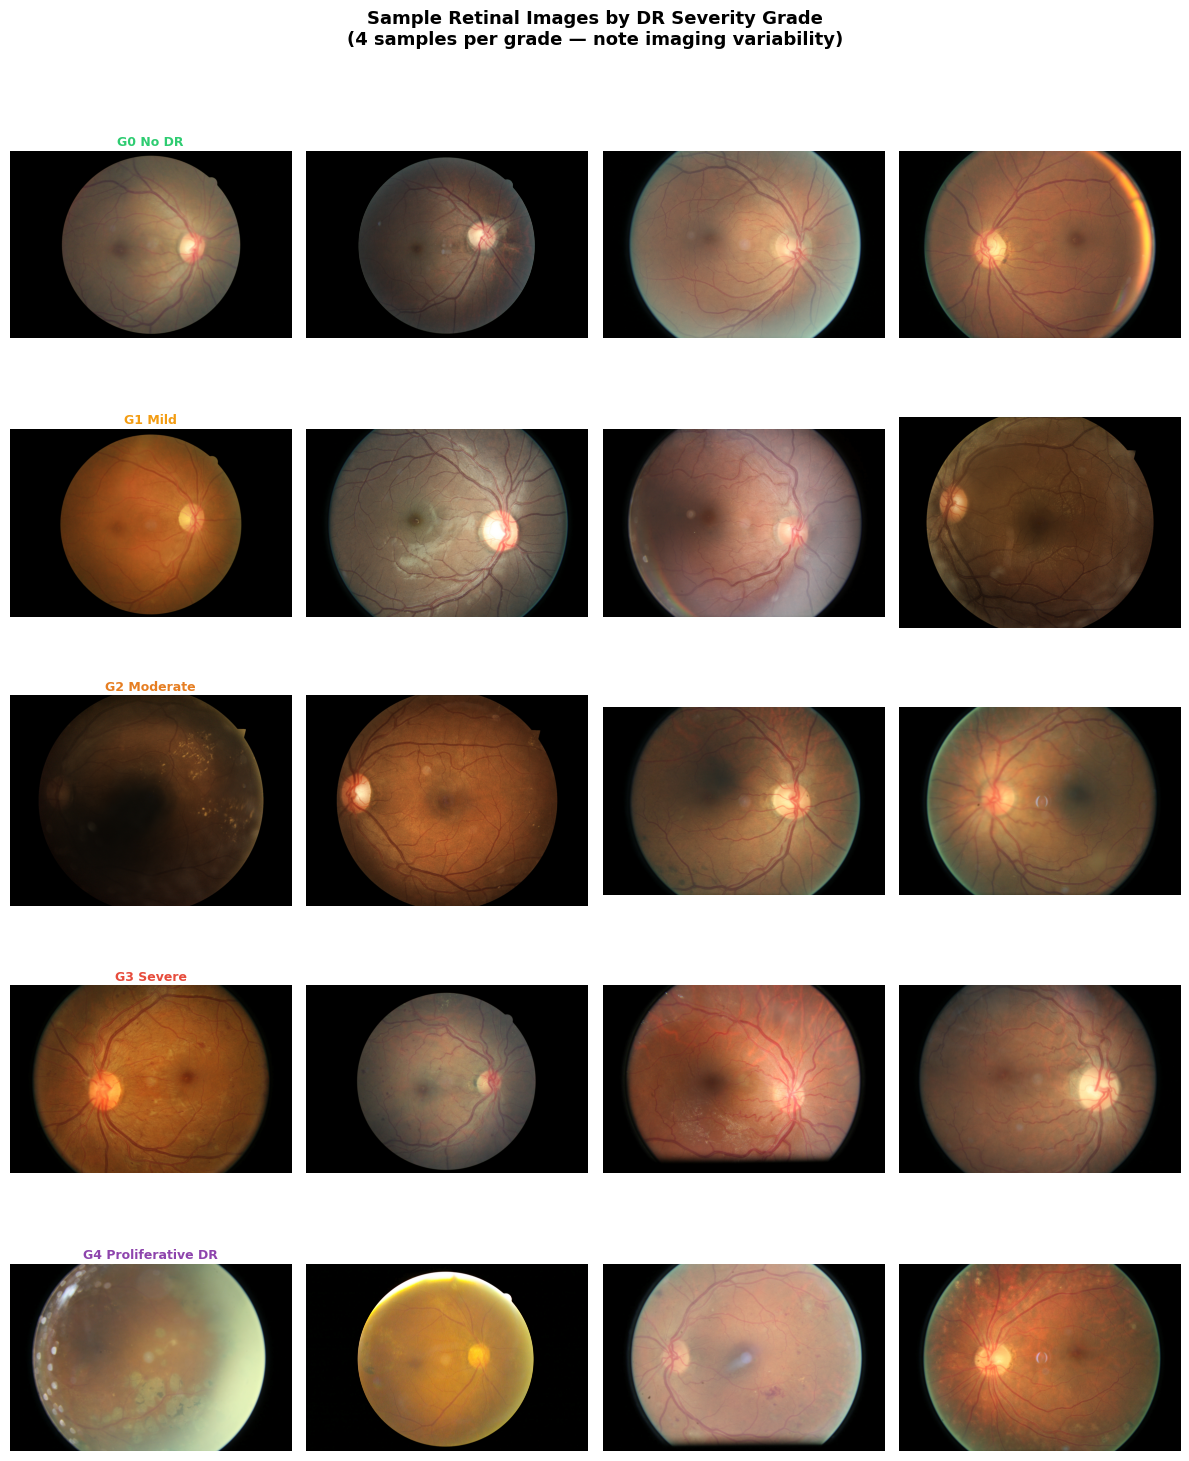

Saved → outputs/figures/sample_images_per_grade.png


In [16]:
# ── Figure 2: Sample images per grade ─────────────────────────
# Show 4 samples per grade to capture variability
N_SAMPLES = 4
fig, axes = plt.subplots(5, N_SAMPLES, figsize=(N_SAMPLES*3, 5*3))

for grade in range(5):
    grade_df = df[df['level'] == grade].sample(
        n=min(N_SAMPLES, len(df[df['level']==grade])),
        random_state=SEED
    )
    for j, (_, row) in enumerate(grade_df.iterrows()):
        ax = axes[grade][j]
        try:
            img = Image.open(row['img_path']).convert('RGB')
            ax.imshow(img)
        except Exception as e:
            ax.text(0.5, 0.5, f'Error:\n{e}', transform=ax.transAxes,
                    ha='center', va='center', fontsize=7)
        title = f'G{grade} {CLASS_NAMES[grade]}' if j == 0 else ''
        ax.set_title(title, fontsize=9, fontweight='bold',
                     color=CLASS_COLORS[grade], pad=4)
        ax.set_xlabel(f'{row["image"]}\n{row["eye"]} eye', fontsize=7)
        ax.axis('off')

plt.suptitle('Sample Retinal Images by DR Severity Grade\n(4 samples per grade — note imaging variability)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'sample_images_per_grade.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved → outputs/figures/sample_images_per_grade.png')

Sampling 500 images for resolution analysis...


  0%|          | 0/500 [00:00<?, ?it/s]


Resolution stats (n=500 images):
  Width: min=400, max=4928, mean=3596, median=3888
  Height: min=315, max=3264, mean=2454, median=2592
  Aspect ratio: mean=1.455, std=0.078


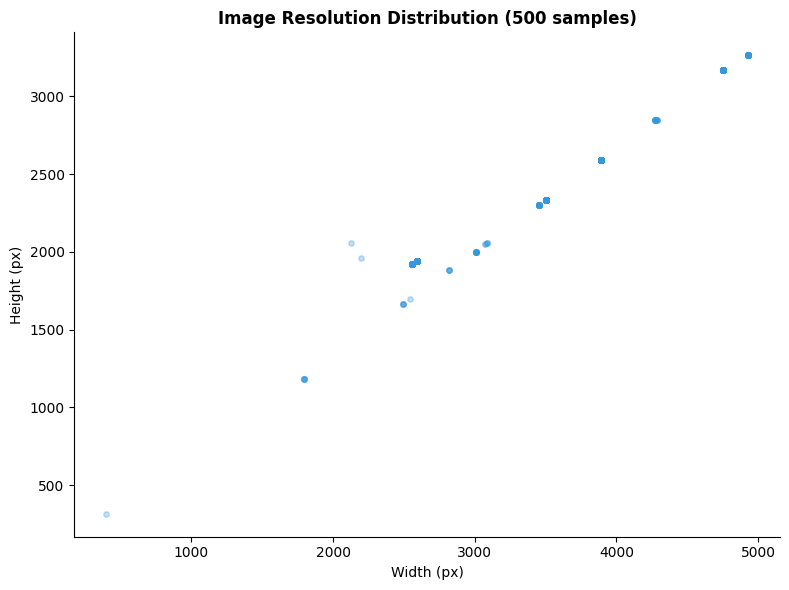

In [18]:
# ── Image resolution analysis (sample 500 images) ─────────────
print('Sampling 500 images for resolution analysis...')
sample_df = df.sample(n=min(500, len(df)), random_state=SEED)

widths, heights, aspects = [], [], []
for _, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    try:
        with Image.open(row['img_path']) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
            aspects.append(w/h)
    except:
        pass

print(f'\nResolution stats (n={len(widths)} images):')
for name, vals in [('Width', widths), ('Height', heights)]:
    print(f'  {name}: min={min(vals)}, max={max(vals)}, '
          f'mean={np.mean(vals):.0f}, median={np.median(vals):.0f}')
print(f'  Aspect ratio: mean={np.mean(aspects):.3f}, std={np.std(aspects):.3f}')

# Resolution scatter plot
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(widths, heights, alpha=0.3, s=15, color='#3498DB')
ax.set_xlabel('Width (px)')
ax.set_ylabel('Height (px)')
ax.set_title('Image Resolution Distribution (500 samples)', fontweight='bold')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'resolution_scatter.png', dpi=120, bbox_inches='tight')
plt.show()

Analysing brightness across grades...


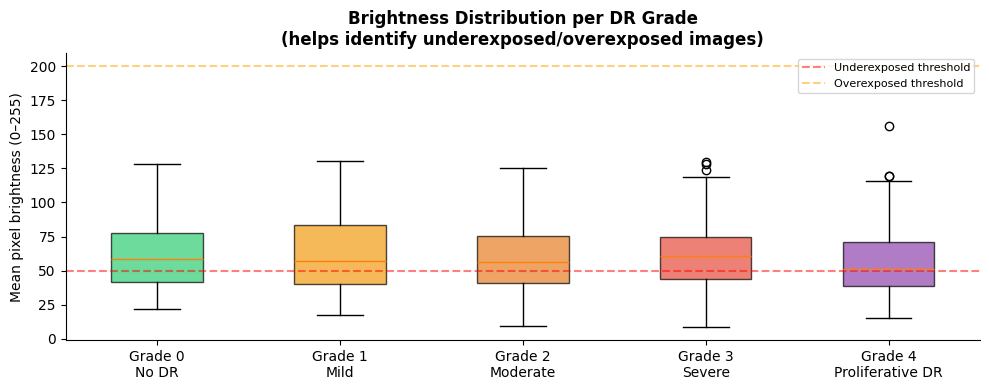

In [19]:
# ── Brightness & quality analysis ─────────────────────────────
# Detects underexposed / overexposed images that may be noise

print('Analysing brightness across grades...')
brightness_by_grade = {g: [] for g in range(5)}

for grade in range(5):
    grade_sample = df[df['level']==grade].sample(
        n=min(100, len(df[df['level']==grade])), random_state=SEED
    )
    for _, row in grade_sample.iterrows():
        try:
            img = Image.open(row['img_path']).convert('L')  # grayscale
            stat = ImageStat.Stat(img)
            brightness_by_grade[grade].append(stat.mean[0])
        except:
            pass

fig, ax = plt.subplots(figsize=(10, 4))
data = [brightness_by_grade[g] for g in range(5)]
bp = ax.boxplot(data, patch_artist=True, notch=False)
for patch, color in zip(bp['boxes'], CLASS_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_xticklabels([f'Grade {i}\n{CLASS_NAMES[i]}' for i in range(5)])
ax.set_ylabel('Mean pixel brightness (0–255)')
ax.set_title('Brightness Distribution per DR Grade\n(helps identify underexposed/overexposed images)',
             fontweight='bold')
ax.axhline(y=50,  color='red',   linestyle='--', alpha=0.5, label='Underexposed threshold')
ax.axhline(y=200, color='orange',linestyle='--', alpha=0.5, label='Overexposed threshold')
ax.legend(fontsize=8)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'brightness_by_grade.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Train / Validation Split

> We use a **stratified split** to ensure both sets have proportionally identical class distributions. This is critical given the severe imbalance.

In [20]:
TRAIN_RATIO = 0.80
VAL_RATIO   = 0.20

train_df, val_df = train_test_split(
    df,
    test_size=VAL_RATIO,
    random_state=SEED,
    stratify=df['level']   # preserve class ratios
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print(f'Split: {TRAIN_RATIO:.0%} train / {VAL_RATIO:.0%} val')
print(f'Train: {len(train_df):,} | Val: {len(val_df):,}\n')

# Verify stratification held
print('Grade  | Train count (%)  | Val count (%)')
print('-'*52)
for g in range(5):
    tc = (train_df['level']==g).sum()
    vc = (val_df['level']==g).sum()
    print(f'  {g}  {CLASS_NAMES[g]:18s}| {tc:5,} ({tc/len(train_df)*100:.1f}%)   | '
          f'{vc:4,} ({vc/len(val_df)*100:.1f}%)')

Split: 80% train / 20% val
Train: 28,100 | Val: 7,026

Grade  | Train count (%)  | Val count (%)
----------------------------------------------------
  0  No DR             | 20,648 (73.5%)   | 5,162 (73.5%)
  1  Mild              | 1,954 (7.0%)   |  489 (7.0%)
  2  Moderate          | 4,234 (15.1%)   | 1,058 (15.1%)
  3  Severe            |   698 (2.5%)   |  175 (2.5%)
  4  Proliferative DR  |   566 (2.0%)   |  142 (2.0%)


## 8. Class Imbalance Handling

> Two complementary strategies applied simultaneously:
> - **WeightedRandomSampler** — balances class frequency at batch construction level
> - **class_weights** in loss function — penalises rare class errors more heavily

In [21]:
def compute_class_weights(labels: list, num_classes: int = 5,
                          device: torch.device = torch.device('cpu')) -> torch.Tensor:
    """Compute inverse-frequency class weights for CrossEntropyLoss.

    Args:
        labels      : list of integer class labels from training set
        num_classes : number of target classes (5 for DR grading)
        device      : torch device to place the weight tensor on

    Returns:
        Tensor of shape (num_classes,) with inverse-frequency weights,
        normalised so weights sum to num_classes.
    """
    labels = np.array(labels)
    counts = np.bincount(labels, minlength=num_classes).astype(float)
    weights = 1.0 / (counts + 1e-6)
    weights = weights / weights.sum() * num_classes  # normalise
    return torch.tensor(weights, dtype=torch.float32).to(device)


def compute_sample_weights(labels: list, num_classes: int = 5) -> list:
    """Compute per-sample weights for WeightedRandomSampler.

    Each sample's weight equals 1 / frequency_of_its_class.
    Higher weight → sampled more often per epoch.

    Args:
        labels      : list of integer class labels from training set
        num_classes : number of target classes

    Returns:
        List of float weights, one per sample.
    """
    labels  = np.array(labels)
    counts  = np.bincount(labels, minlength=num_classes).astype(float)
    cw      = 1.0 / (counts + 1e-6)
    return [float(cw[lbl]) for lbl in labels]


DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
class_weights   = compute_class_weights(train_df['level'].tolist(), device=DEVICE)
sample_weights  = compute_sample_weights(train_df['level'].tolist())

print('Class weights (for CrossEntropyLoss):')
for i, (name, w) in enumerate(zip(CLASS_NAMES.values(), class_weights.cpu().tolist())):
    print(f'  Grade {i} {name:18s}: {w:.4f}')
print(f'\nHighest weight → most penalised when wrong')

Class weights (for CrossEntropyLoss):
  Grade 0 No DR             : 0.0606
  Grade 1 Mild              : 0.6404
  Grade 2 Moderate          : 0.2955
  Grade 3 Severe            : 1.7927
  Grade 4 Proliferative DR  : 2.2108

Highest weight → most penalised when wrong
